# Multimodal Movie Genre Classification on MM-IMDb

**Can a movie's poster and its plot summary, used together, predict its genres better than either one alone?**

This notebook is the whole project in one place. It predicts a movie's genres (multi-label, 23 genres) from its **poster** (image) and **plot summary** (text), and compares four models:

| Model | Input | Fusion |
|---|---|---|
| Poster only | CLIP image embedding | none (unimodal baseline) |
| Plot only | MPNet text embedding | none (unimodal baseline) |
| Early fusion | poster and plot embeddings concatenated | feature level, one shared classifier |
| Late fusion | the two baselines' predicted probabilities | decision level, weighted average |

Results are compared with the published state of the art on this dataset, the Gated Multimodal Unit (GMU) of Arevalo et al. (2017).



### Contents
1. Setup
2. Configuration
3. Data: download and unpack
4. Loading and cleaning
5. Data quality assessment
6. Feature extraction (frozen encoders)
7. Models and evaluation metrics
8. Training and evaluation
9. Results: tables and figures


## 1. Setup
Installs the few libraries Colab does not have, connects Google Drive and reads the Kaggle token.

In [1]:
%pip -q install open_clip_torch sentence-transformers kagglehub h5py

In [2]:
import csv, json, os, random, re, shutil, time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image
from sklearn.metrics import average_precision_score, f1_score, hamming_loss
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    WORK_DIR = Path('/content/drive/MyDrive/mmimdb_work')   # kept between sessions
    LOCAL_DIR = Path('/content/data')                       # fast local disk, wiped when Colab resets
    try:
        os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
    except Exception as e:
        print('Kaggle token secret not found:', e)
else:
    WORK_DIR = Path(os.environ.get('MMIMDB_WORK_DIR', 'mmimdb_work'))
    LOCAL_DIR = WORK_DIR / 'local'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| outputs in', WORK_DIR)

Mounted at /content/drive
Kaggle token secret not found: Requesting secret KAGGLE_API_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.
Device: cuda | outputs in /content/drive/MyDrive/mmimdb_work


## 2. Configuration
Paths, the 23 genres, the two pretrained encoders, the training settings and the published reference results.

In [3]:
RAW_DIR = LOCAL_DIR / 'raw' / 'mmimdb'        # unpacked posters (.jpeg) + plots (.json)
PREDS_DIR = LOCAL_DIR / 'preds'               # predicted probabilities per model, seed and split
FEATURES_DIR = WORK_DIR / 'features'          # cached embeddings
RESULTS_DIR = WORK_DIR / 'results'
FIGURES_DIR = RESULTS_DIR / 'figures'
TABLES_DIR = RESULTS_DIR / 'tables'
HISTORY_DIR = RESULTS_DIR / 'history'         # per-epoch train/dev curves
PER_GENRE_DIR = RESULTS_DIR / 'per_genre'     # per-genre test scores
for d in (RAW_DIR, PREDS_DIR, FEATURES_DIR, FIGURES_DIR, TABLES_DIR, HISTORY_DIR, PER_GENRE_DIR):
    d.mkdir(parents=True, exist_ok=True)

DATASET = 'johnarevalo/mmimdb'                         # Kaggle dataset id
LOCAL_SOURCE = os.environ.get('MMIMDB_SOURCE')         # optional: folder already holding the Kaggle files

# The 23 genres used by Arevalo et al. (2017); rarer tags are dropped.
GENRES = ['Drama', 'Comedy', 'Romance', 'Thriller', 'Crime', 'Action', 'Adventure',
          'Horror', 'Documentary', 'Mystery', 'Sci-Fi', 'Fantasy', 'Family',
          'Biography', 'War', 'History', 'Music', 'Animation', 'Musical', 'Western',
          'Sport', 'Short', 'Film-Noir']

# Frozen pretrained encoders (OpenAI's CLIP weights need the QuickGELU variant).
IMAGE_ENCODER = ('ViT-B-32-quickgelu', 'openai')
TEXT_ENCODER = 'sentence-transformers/all-mpnet-base-v2'
ENCODERS = {'image': list(IMAGE_ENCODER), 'text': TEXT_ENCODER}

SEEDS = [0, 1, 2]
SPLITS = ('train', 'dev', 'test')
MODELS = ('image', 'text', 'early', 'late')
MODEL_LABELS = {'image': 'Poster only', 'text': 'Plot only',
                'early': 'Early fusion (concat)', 'late': 'Late fusion (weighted avg)'}
COLORS = {'image': '#DD8452', 'text': '#55A868', 'early': '#4C72B0', 'late': '#8172B3'}

TRAIN_CFG = dict(epochs=100, patience=8, batch_size=256, lr=1e-3, weight_decay=1e-2,
                 hidden=512, dropout=0.3)

# Test-set F-scores reported by Arevalo et al. (2017), Table 2 (state-of-the-art reference).
PAPER_RESULTS = {
    'GMU (Arevalo et al., 2017)':          {'weighted_f1': 0.617, 'samples_f1': 0.630, 'micro_f1': 0.630, 'macro_f1': 0.541},
    'Concatenate (Arevalo et al., 2017)':  {'weighted_f1': 0.597, 'samples_f1': 0.605, 'micro_f1': 0.606, 'macro_f1': 0.521},
    'AVG_probs (Arevalo et al., 2017)':    {'weighted_f1': 0.604, 'samples_f1': 0.616, 'micro_f1': 0.615, 'macro_f1': 0.491},
    'Text MaxoutMLP_w2v (Arevalo et al.)': {'weighted_f1': 0.588, 'samples_f1': 0.592, 'micro_f1': 0.595, 'macro_f1': 0.488},
    'Visual VGG_Transfer (Arevalo et al.)':{'weighted_f1': 0.410, 'samples_f1': 0.429, 'micro_f1': 0.437, 'macro_f1': 0.284},
}

# Training-set count per genre, Arevalo et al. (2017), Table 1: used to name the unlabelled genre columns.
PAPER_TRAIN_COUNTS = {
    'Drama': 8424, 'Comedy': 5108, 'Romance': 3226, 'Thriller': 3113, 'Crime': 2293,
    'Action': 2155, 'Adventure': 1611, 'Horror': 1603, 'Documentary': 1234, 'Mystery': 1231,
    'Sci-Fi': 1212, 'Fantasy': 1162, 'Family': 978, 'Biography': 788, 'War': 806,
    'History': 680, 'Music': 634, 'Animation': 586, 'Musical': 503, 'Western': 423,
    'Sport': 379, 'Short': 281, 'Film-Noir': 202,
}


def save_fig(fig, name):
    # Save a figure to results/figures and show it in the notebook.
    fig.savefig(FIGURES_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def to_md(df):
    lines = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)]
    lines += ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in df.itertuples(index=False)]
    return '\n'.join(lines) + '\n'


def features_up_to_date():
    # True if all cached embeddings exist and were made with the encoders configured above.
    meta = FEATURES_DIR / 'encoders.json'
    if not (meta.exists() and (FEATURES_DIR / 'test_text.npy').exists()):
        return False
    return json.loads(meta.read_text()) == ENCODERS


FEATURES_DONE = features_up_to_date()
print('Embeddings already cached:', FEATURES_DONE)

Embeddings already cached: True


## 3. Data: download and unpack

The Kaggle release of MM-IMDb (Arevalo et al., 2017) is packed in two files:
- `multimodal_imdb.hdf5`: posters as integer arrays (3 × 256 × 160), a 23-column genre matrix with **unnamed** columns, IMDb ids, the official train/dev/test split, and each plot as a sequence of **word indices**;
- `metadata.npy`: the vocabulary that turns word indices back into words.

The functions below unpack them into one poster image and one JSON record (plot + genres) per movie. Two checks are built in:
- **Genre names**: each unnamed column is identified by matching its training-set count to the per-genre counts in Table 1 of the paper. An exact match for all 23 confirms both the labels and the official split.
- **Plots**: rebuilt from word indices, so they are lower-case and tokenised; out-of-vocabulary words (`_UNK_`) are removed and counted.

In [4]:
UNK_TOKENS = {'_UNK_', '<unk>', 'UNK'}
_SPACE_BEFORE = re.compile(r"\s+([.,;:!?%)\]}'])")
_SPACE_AFTER = re.compile(r"([(\[{$])\s+")


def h5_datasets(f):
    out = {}
    f.visititems(lambda n, o: out.__setitem__(n, o) if isinstance(o, h5py.Dataset) else None)
    return out


def load_npy(path):
    obj = np.load(path, allow_pickle=True)
    return obj.item() if isinstance(obj, np.ndarray) and obj.shape == () else obj


def norm_id(x):
    if isinstance(x, (bytes, np.bytes_)):
        x = x.decode()
    s = str(x).strip()
    s = s[2:] if s.startswith('tt') else s
    return s.zfill(7) if s.isdigit() else s


def norm_split(s):
    s = (s.decode() if isinstance(s, bytes) else str(s)).lower()
    return {'train': 'train', 'dev': 'dev', 'valid': 'dev', 'val': 'dev',
            'validation': 'dev', 'test': 'test'}.get(s)


def describe_hdf5(h5_path):
    with h5py.File(h5_path, 'r') as f:
        for name, d in h5_datasets(f).items():
            print(f'  dataset {name:22s} shape={d.shape} dtype={d.dtype}')


def find_images(ds):
    # The poster array: 4-D integers with a channel axis of size 1 or 3.
    cands = [(n, d) for n, d in ds.items()
             if d.ndim == 4 and np.issubdtype(d.dtype, np.integer)
             and (d.shape[1] in (1, 3) or d.shape[-1] in (1, 3))]
    named = [c for c in cands if 'image' in c[0].lower() or 'poster' in c[0].lower()]
    if not (named or cands):
        raise ValueError('No poster image array found in the HDF5 file.')
    return (named or cands)[0]


def read_split(f):
    # Fuel stores the official split as row ranges in the 'split' attribute.
    ranges = {}
    for row in f.attrs.get('split', []):
        split = norm_split(row['split'])
        if split and split not in ranges:
            ranges[split] = (int(row['start']), int(row['stop']))
    if not {'train', 'dev', 'test'} <= set(ranges):
        raise ValueError(f'Could not read the train/dev/test split (got {ranges}).')
    return ranges


def name_genre_columns(y_train):
    # Match each label column to a genre by its training-set count (paper, Table 1).
    counts = y_train.sum(0).astype(int)
    by_count = {c: g for g, c in PAPER_TRAIN_COUNTS.items()}
    if len(set(counts)) == len(counts) and all(c in by_count for c in counts):
        return [by_count[c] for c in counts], "exact match to the paper's per-genre training counts"
    names, free = [], dict(PAPER_TRAIN_COUNTS)
    for c in counts:  # fallback: nearest count, each genre used once
        g = min(free, key=lambda k: abs(free[k] - c))
        names.append(g)
        free.pop(g)
    return names, 'WARNING: approximate match (counts differ from the paper)'


def find_vocabulary(meta):
    # Return index -> word from whatever structure metadata.npy uses.
    pools = list(meta.values()) + [meta] if isinstance(meta, dict) else list(meta)
    best = {}
    for p in pools:
        cand = {}
        if isinstance(p, dict) and p:
            k, v = next(iter(p.items()))
            if isinstance(k, str) and isinstance(v, (int, np.integer)):
                cand = {int(i): w for w, i in p.items()}
            elif isinstance(k, (int, np.integer)) and isinstance(v, str):
                cand = {int(i): w for i, w in p.items()}
        elif isinstance(p, (list, tuple, np.ndarray)) and len(p) and isinstance(p[0], str):
            cand = dict(enumerate(p))
        if len(cand) > len(best):
            best = cand
    if len(best) < 1000:
        raise ValueError('Could not find a word vocabulary in metadata.npy.')
    return best


def decode_plot(seq, ix_to_word):
    words, unk = [], 0
    for i in np.asarray(seq).ravel():
        w = ix_to_word.get(int(i))
        if w is None or w in UNK_TOKENS:
            unk += 1
            continue
        words.append(w)
    text = _SPACE_AFTER.sub(r'\1', _SPACE_BEFORE.sub(r'\1', ' '.join(words)))
    return text, len(words), unk


def to_pil(img):
    img = np.clip(img, 0, 255).astype(np.uint8)
    if img.shape[0] in (1, 3) and img.shape[-1] not in (1, 3):
        img = np.transpose(img, (1, 2, 0))  # CHW -> HWC
    if img.shape[-1] == 1:
        img = img[..., 0]
    return Image.fromarray(img).convert('RGB')


def convert_hdf5(h5_path, meta_path, out_root, chunk=256):
    items = out_root / 'dataset'
    items.mkdir(parents=True, exist_ok=True)
    ix_to_word = find_vocabulary(load_npy(meta_path))
    print(f'Vocabulary: {len(ix_to_word):,} words')
    with h5py.File(h5_path, 'r') as f:
        ds = h5_datasets(f)
        img_name, imgs = find_images(ds)
        n = imgs.shape[0]
        ranges = read_split(f)
        print(f"Posters: '{img_name}' {imgs.shape} {imgs.dtype} | split: {ranges}")
        y = ds['genres'][:]
        a, b = ranges['train']
        col_names, how = name_genre_columns(y[a:b])
        print(f'Genre columns named by {how}:\n  {col_names}')
        ids = [norm_id(x) for x in ds['imdb_ids'][:]] if 'imdb_ids' in ds else [f'{k:07d}' for k in range(n)]
        seqs = ds['sequences']
        total_words = total_unk = empty = 0
        samples = []
        for start in tqdm(range(0, n, chunk), desc='unpacking posters and plots'):
            block, seq_block = imgs[start:start + chunk], seqs[start:start + chunk]
            for j in range(len(block)):
                k = start + j
                to_pil(block[j]).save(items / f'{ids[k]}.jpeg', quality=95)
                plot, nw, nu = decode_plot(seq_block[j], ix_to_word)
                total_words += nw
                total_unk += nu
                empty += plot == ''
                if len(samples) < 3 and plot:
                    samples.append(plot[:300])
                genres = [col_names[c] for c in np.flatnonzero(y[k] > 0)]
                with open(items / f'{ids[k]}.json', 'w') as fh:
                    json.dump({'plot': plot, 'genres': genres}, fh)
    split = {s: [ids[k] for k in range(a, b)] for s, (a, b) in ranges.items()}
    (out_root / 'split.json').write_text(json.dumps(split))
    report = {'movies': n, 'split_sizes': {s: len(v) for s, v in split.items()},
              'poster_array': {'shape': list(imgs.shape[1:]), 'stored_dtype': str(imgs.dtype)},
              'genre_column_mapping': how, 'genre_columns': col_names,
              'vocabulary_size': len(ix_to_word), 'plot_tokens_kept': total_words,
              'plot_tokens_unknown_removed': total_unk,
              'unknown_token_rate': round(total_unk / max(total_words + total_unk, 1), 4),
              'empty_plots': empty, 'example_plots': samples}
    (RESULTS_DIR / 'conversion_report.json').write_text(json.dumps(report, indent=1))
    if empty > 0.5 * n:
        raise ValueError('Most rebuilt plots are empty: the vocabulary does not match the sequences.')
    return report


def get_dataset():
    # Download from Kaggle (or use MMIMDB_SOURCE) and unpack into RAW_DIR, unless already done.
    if (RAW_DIR / 'split.json').exists():
        print('Dataset already unpacked in', RAW_DIR)
        return
    if LOCAL_SOURCE:
        src = Path(LOCAL_SOURCE)
    else:
        import kagglehub
        print(f'Downloading {DATASET} (~15.7 GB; Colab usually has it cached)...')
        src = Path(kagglehub.dataset_download(DATASET))
    h5 = next(iter(sorted(src.rglob('*.hdf5'))), None)
    meta = next(iter(sorted(src.rglob('metadata.npy'))), None)
    if h5 is None or meta is None:
        raise FileNotFoundError(f'Expected multimodal_imdb.hdf5 and metadata.npy in {src}')
    print('Source:', src)
    describe_hdf5(h5)
    report = convert_hdf5(h5, meta, RAW_DIR)
    print(json.dumps({k: v for k, v in report.items() if k != 'example_plots'}, indent=1))

In [5]:
NEED_RAW = not FEATURES_DONE or not (RESULTS_DIR / 'data_quality.json').exists()
if NEED_RAW:
    get_dataset()
else:
    print('Embeddings and data-quality results already exist: skipping the download.')

Embeddings and data-quality results already exist: skipping the download.


## 4. Loading and cleaning
One row per movie with its split, plot, genres and poster path. Four cleaning rules are applied and their effect is recorded:
1. keep only movies in the official train/dev/test split;
2. drop movies with none of the 23 genres (nothing to predict);
3. drop movies with a missing poster;
4. drop movies with an empty plot.

Images are resized and normalised, and text is tokenised, later by each encoder's own preprocessing.

In [6]:
def load_metadata():
    split_of = {i: s for s, ids in json.loads((RAW_DIR / 'split.json').read_text()).items() for i in ids}
    rows = []
    for jp in sorted((RAW_DIR / 'dataset').glob('*.json')):
        meta = json.loads(jp.read_text())
        all_genres = meta.get('genres', []) or []
        rows.append({'id': jp.stem, 'split': norm_split(split_of.get(jp.stem, 'unsplit')) or 'unsplit',
                     'plot': ' '.join(str(meta.get('plot', '')).split()),
                     'all_genres': all_genres,
                     'genres': [g for g in all_genres if g in GENRES],
                     'poster_path': str(RAW_DIR / 'dataset' / f'{jp.stem}.jpeg')})
    return pd.DataFrame(rows)


def preprocess(df):
    report = {'start': len(df)}
    df = df[df['split'].isin(SPLITS)]
    report['after_split_filter'] = len(df)
    df = df[df['genres'].map(len) > 0]
    report['after_no_genre_filter'] = len(df)
    df = df[df['poster_path'].map(os.path.exists)]
    report['after_missing_poster_filter'] = len(df)
    df = df[df['plot'].str.len() > 0]
    report['after_empty_plot_filter'] = len(df)
    report['per_split'] = df['split'].value_counts().to_dict()
    return df.reset_index(drop=True), report


def encode_labels(genres_col):
    # Multi-hot matrix (n, 23), column order = GENRES.
    idx = {g: i for i, g in enumerate(GENRES)}
    y = np.zeros((len(genres_col), len(GENRES)), dtype=np.float32)
    for r, gs in enumerate(genres_col):
        for g in gs:
            y[r, idx[g]] = 1.0
    return y


if NEED_RAW:
    raw = load_metadata()
    df, clean_report = preprocess(raw)
    print(json.dumps(clean_report, indent=1))
    display(df.head(3))

## 5. Data quality assessment
Missing and corrupt data, duplicates, label imbalance, label cardinality, genre co-occurrence and plot length.

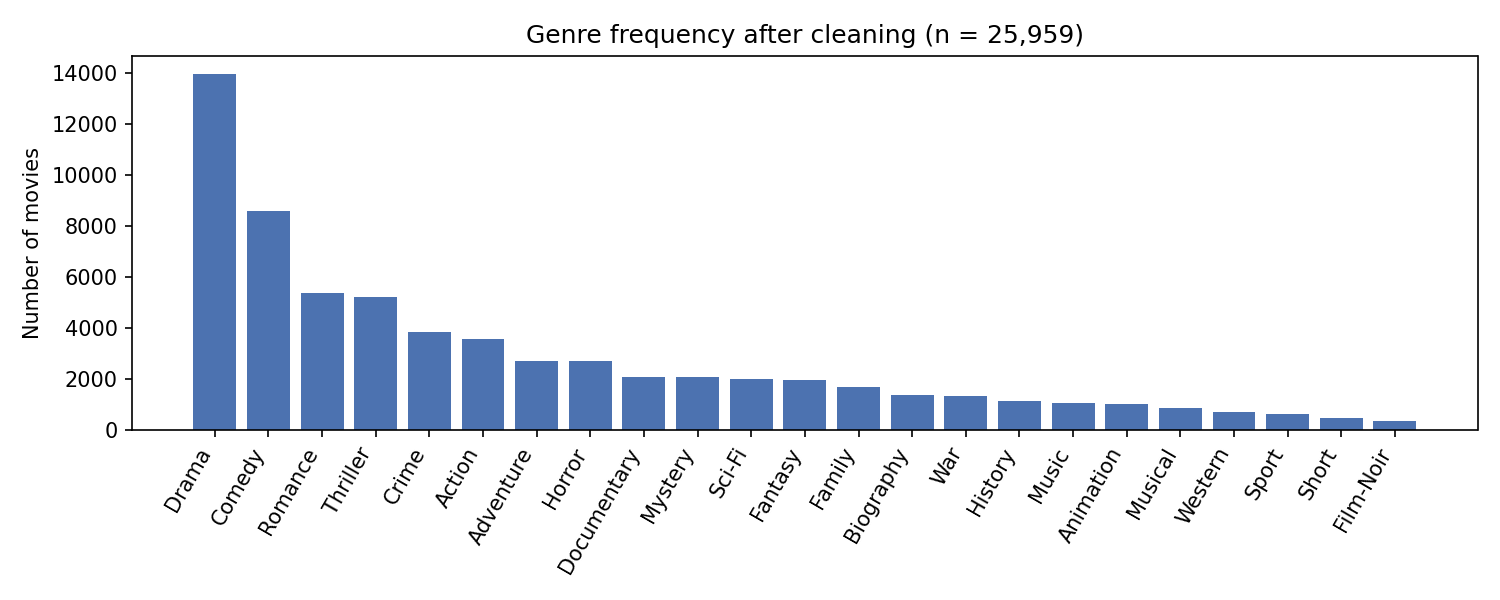

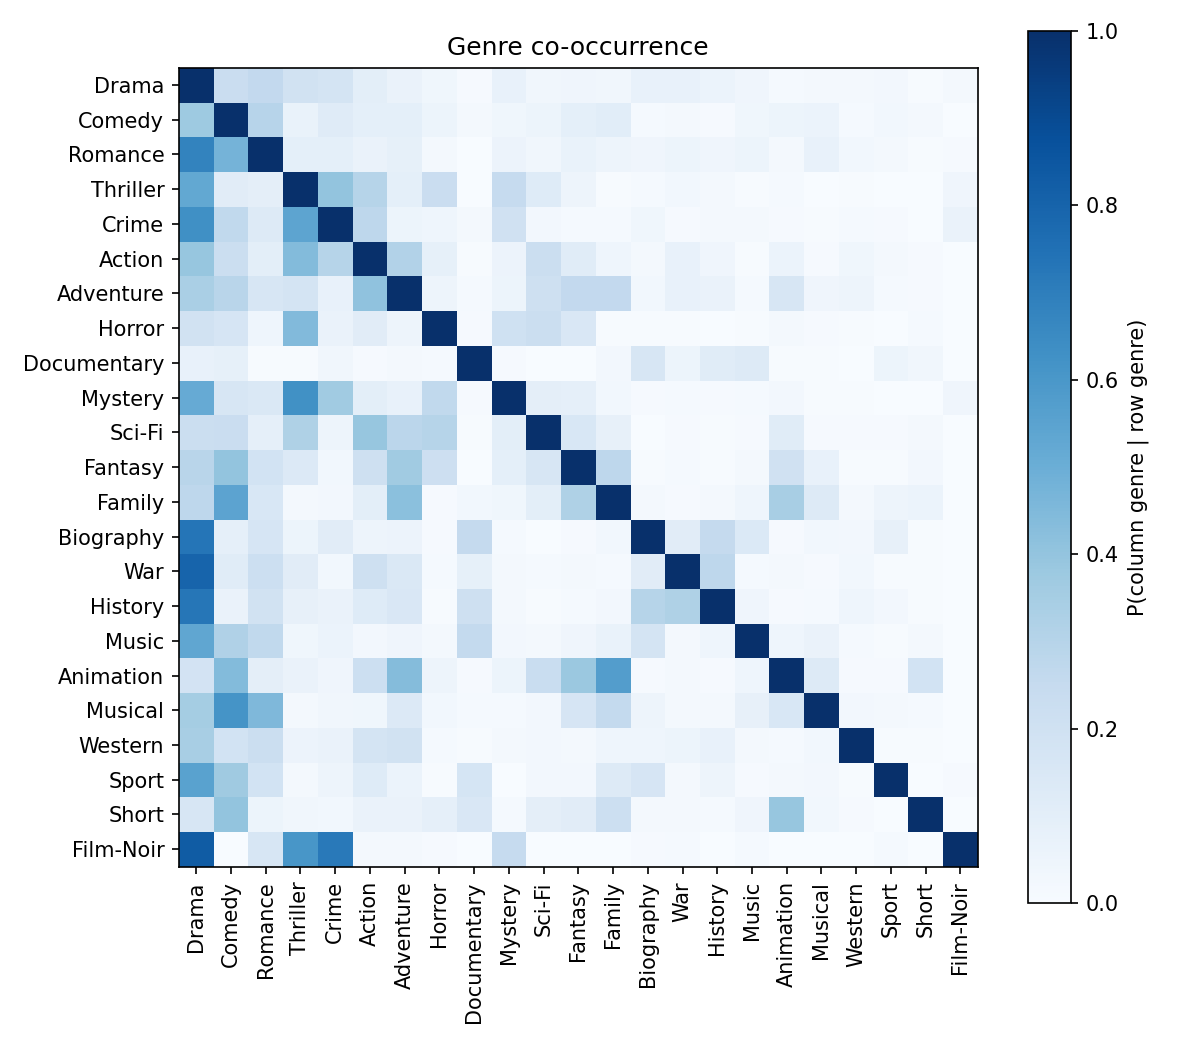

{
 "movies_total": 25959,
 "split_sizes_raw": {
  "train": 15552,
  "test": 7799,
  "dev": 2608
 },
 "missing_posters": 0,
 "empty_plots": 0,
 "no_in_scope_genre": 0,
 "duplicate_plots": 14,
 "out_of_scope_genres_dropped": [],
 "corrupt_posters": 0,
 "poster_width_median": 160,
 "poster_height_median": 256,
 "cleaning": {
  "start": 25959,
  "after_split_filter": 25959,
  "after_no_genre_filter": 25959,
  "after_missing_poster_filter": 25959,
  "after_empty_plot_filter": 25959,
  "per_split": {
   "train": 15552,
   "test": 7799,
   "dev": 2608
  }
 },
 "mean_genres_per_movie": 2.48,
 "imbalance_ratio_max_over_min": 41.3,
 "plot_words": {
  "median": 95,
  "p95": 267,
  "max": 1725,
  "share_over_384_tokens_approx": 0.03
 }
}


In [7]:
def data_quality(raw, df):
    q = {'movies_total': len(raw), 'split_sizes_raw': raw['split'].value_counts().to_dict(),
         'missing_posters': int((~raw['poster_path'].map(os.path.exists)).sum()),
         'empty_plots': int((raw['plot'] == '').sum()),
         'no_in_scope_genre': int((raw['genres'].map(len) == 0).sum()),
         'duplicate_plots': int(raw.loc[raw['plot'] != '', 'plot'].duplicated().sum())}
    bad, sizes = 0, []
    for p in tqdm(df['poster_path'], desc='checking posters'):
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                sizes.append(im.size)
        except Exception:
            bad += 1
    q['corrupt_posters'] = bad
    q['poster_width_median'], q['poster_height_median'] = (int(v) for v in np.median(np.array(sizes), 0))
    q['cleaning'] = clean_report

    y = encode_labels(df['genres'])
    counts = y.sum(0)
    q['mean_genres_per_movie'] = round(float(y.sum(1).mean()), 2)
    q['genre_counts'] = {g: int(c) for g, c in zip(GENRES, counts)}
    q['imbalance_ratio_max_over_min'] = round(float(counts.max() / max(counts.min(), 1)), 1)
    words = df['plot'].str.split().str.len()
    q['plot_words'] = {'median': int(words.median()), 'p95': int(words.quantile(.95)), 'max': int(words.max()),
                       'share_over_384_tokens_approx': round(float((words > 300).mean()), 3)}
    (RESULTS_DIR / 'data_quality.json').write_text(json.dumps(q, indent=1))

    order = counts.argsort()[::-1]
    fig = plt.figure(figsize=(10, 4))
    plt.bar([GENRES[i] for i in order], counts[order], color='#4C72B0')
    plt.xticks(rotation=60, ha='right'); plt.ylabel('Number of movies')
    plt.title(f'Genre frequency after cleaning (n = {len(df):,})')
    save_fig(fig, 'genre_frequency')

    fig = plt.figure(figsize=(6, 4))
    plt.hist(words.clip(upper=words.quantile(.99)), bins=50, color='#55A868')
    plt.xlabel('Plot length (words, clipped at 99th percentile)'); plt.ylabel('Number of movies')
    plt.title('Plot summary length')
    save_fig(fig, 'plot_length')

    fig = plt.figure(figsize=(6, 4))
    plt.bar(*np.unique(y.sum(1).astype(int), return_counts=True), color='#C44E52')
    plt.xlabel('Genres per movie'); plt.ylabel('Number of movies'); plt.title('Label cardinality (multi-label)')
    save_fig(fig, 'labels_per_movie')

    co = ((y.T @ y) / np.maximum(counts[:, None], 1))[np.ix_(order, order)]  # P(column | row)
    names = [GENRES[i] for i in order]
    fig = plt.figure(figsize=(8, 7))
    plt.imshow(co, cmap='Blues', vmin=0, vmax=1)
    plt.xticks(range(len(names)), names, rotation=90); plt.yticks(range(len(names)), names)
    plt.colorbar(label='P(column genre | row genre)'); plt.title('Genre co-occurrence')
    save_fig(fig, 'genre_cooccurrence')
    return q


if not (RESULTS_DIR / 'data_quality.json').exists():
    q = data_quality(raw, df)
else:
    q = json.loads((RESULTS_DIR / 'data_quality.json').read_text())
    for name in ('genre_frequency', 'genre_cooccurrence'):
        if (FIGURES_DIR / f'{name}.png').exists():
            display(Image.open(FIGURES_DIR / f'{name}.png'))
print(json.dumps({k: v for k, v in q.items() if k != 'genre_counts'}, indent=1))

## 6. Feature extraction (frozen encoders)
Each poster and plot becomes one fixed-length vector, computed **once** and cached:
- **Poster**: CLIP ViT-B/32 image encoder (Radford et al., 2021), 512 numbers;
- **Plot**: `all-mpnet-base-v2` sentence-transformer (Reimers & Gurevych, 2019; MPNet, Song et al., 2020), 768 numbers, reading up to 384 tokens.

Both encoders stay frozen and the vectors are L2-normalised. Freezing keeps the project inside a free Colab GPU and avoids overfitting roughly 200 million encoder parameters on 15,552 training movies. The printed time and peak GPU memory are the evidence that the project fits the GPU budget.

In [8]:
class PosterDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return self.transform(im.convert('RGB'))


@torch.no_grad()
def encode_images(paths, batch_size=128):
    import open_clip
    model, _, transform = open_clip.create_model_and_transforms(IMAGE_ENCODER[0], pretrained=IMAGE_ENCODER[1])
    model = model.to(DEVICE).eval()
    loader = DataLoader(PosterDataset(paths, transform), batch_size=batch_size, num_workers=2,
                        pin_memory=DEVICE == 'cuda')
    out = []
    for x in tqdm(loader, desc='posters'):
        with torch.autocast(device_type=DEVICE, enabled=DEVICE == 'cuda'):
            z = model.encode_image(x.to(DEVICE))
        out.append(torch.nn.functional.normalize(z.float(), dim=-1).cpu().numpy())
    return np.concatenate(out).astype(np.float32)


def encode_texts(texts, batch_size=128):
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer(TEXT_ENCODER, device=DEVICE)
    return model.encode(list(texts), batch_size=batch_size, show_progress_bar=True,
                        convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)


if FEATURES_DONE:
    print('Embeddings already cached in', FEATURES_DIR)
else:
    for old in FEATURES_DIR.glob('*.npy'):  # encoders changed or incomplete: start clean
        old.unlink()
    for split in SPLITS:
        part = df[df['split'] == split]
        t0 = time.time()
        img, txt = encode_images(part['poster_path']), encode_texts(part['plot'])
        np.save(FEATURES_DIR / f'{split}_image.npy', img)
        np.save(FEATURES_DIR / f'{split}_text.npy', txt)
        np.save(FEATURES_DIR / f'{split}_labels.npy', encode_labels(part['genres']))
        np.save(FEATURES_DIR / f'{split}_ids.npy', part['id'].to_numpy(dtype=object))
        print(f'{split}: {len(part)} movies, image {img.shape}, text {txt.shape}, {(time.time() - t0) / 60:.1f} min')
        if DEVICE == 'cuda':
            print(f'  peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB')
    (FEATURES_DIR / 'encoders.json').write_text(json.dumps(ENCODERS))

data = {s: {k: np.load(FEATURES_DIR / f'{s}_{k}.npy', allow_pickle=(k == 'ids'))
            for k in ('image', 'text', 'labels', 'ids')} for s in SPLITS}
print({s: (len(data[s]['labels']), data[s]['image'].shape[1], data[s]['text'].shape[1]) for s in SPLITS})

Embeddings already cached in /content/drive/MyDrive/mmimdb_work/features
{'train': (15552, 512, 768), 'dev': (2608, 512, 768), 'test': (7799, 512, 768)}


## 7. Models and evaluation metrics

**Classifier head** (shared by every trainable model, so differences come from the input, not the architecture): LayerNorm → Linear(512) → ReLU → Dropout(0.3) → Linear(23). Each of the 23 outputs is an independent yes/no genre decision (sigmoid + binary cross-entropy), which is what multi-label classification needs.

**Metrics**, because on imbalanced multi-label data each answers a different question:

| Metric | What it tells you |
|---|---|
| Micro-F1 | overall correctness, dominated by common genres (Drama, Comedy) |
| Macro-F1 | average over genres, so rare genres count equally |
| Weighted-F1, samples-F1 | the other F1 variants reported by Arevalo et al. (2017), for direct comparison |
| Mean average precision | threshold-free ranking quality per genre |
| Hamming loss | share of individual genre decisions that are wrong (lower is better) |

**Decision threshold**: one global threshold is chosen on the dev set to maximise micro-F1 and applied unchanged to train and test. A movie left with no genre receives its single most likely one.

In [9]:
class MLPHead(nn.Module):
    def __init__(self, in_dim, n_classes=23, hidden=512, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(in_dim), nn.Linear(in_dim, hidden), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(hidden, n_classes))

    def forward(self, x):
        return self.net(x)


METRIC_COLS = ['micro_f1', 'macro_f1', 'weighted_f1', 'samples_f1', 'mean_ap', 'hamming_loss']


def predict_labels(y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    empty = y_pred.sum(1) == 0
    y_pred[empty, y_prob[empty].argmax(1)] = 1
    return y_pred


def tune_threshold(y_true, y_prob):
    grid = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y_true, predict_labels(y_prob, t), average='micro', zero_division=0) for t in grid]
    return float(grid[int(np.argmax(scores))])


def mean_ap(y_true, y_prob):
    return float(np.mean([average_precision_score(y_true[:, i], y_prob[:, i])
                          for i in range(y_true.shape[1]) if y_true[:, i].sum() > 0]))


def evaluate(y_true, y_prob, threshold):
    y_pred = predict_labels(y_prob, threshold)
    f1 = lambda avg: float(f1_score(y_true, y_pred, average=avg, zero_division=0))
    per_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    per_genre = {g: {'f1': float(per_f1[i]), 'support': int(y_true[:, i].sum()),
                     'ap': float(average_precision_score(y_true[:, i], y_prob[:, i])) if y_true[:, i].sum() else None}
                 for i, g in enumerate(GENRES)}
    return {'micro_f1': f1('micro'), 'macro_f1': f1('macro'), 'weighted_f1': f1('weighted'),
            'samples_f1': f1('samples'), 'mean_ap': mean_ap(y_true, y_prob),
            'hamming_loss': float(hamming_loss(y_true, y_pred)), 'threshold': threshold,
            'per_genre': per_genre}


def log_result(model, seed, split, scores, notes=''):
    # One row per model, seed and split in results/metrics.csv (re-runs replace their rows).
    path = RESULTS_DIR / 'metrics.csv'
    rows = []
    if path.exists():
        with open(path, newline='') as f:
            rows = [r for r in csv.DictReader(f)
                    if not (r['model'] == model and r['seed'] == str(seed) and r['split'] == split)]
    rows.append({'model': model, 'seed': seed, 'split': split,
                 **{k: f'{scores[k]:.4f}' for k in METRIC_COLS},
                 'threshold': f"{scores['threshold']:.2f}", 'notes': notes})
    rows.sort(key=lambda r: (r['model'], int(r['seed']), r['split']))
    with open(path, 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=['model', 'seed', 'split', *METRIC_COLS, 'threshold', 'notes'])
        w.writeheader()
        w.writerows(rows)
    if split == 'test':
        (PER_GENRE_DIR / f'{model}_seed{seed}.json').write_text(json.dumps(scores['per_genre'], indent=1))

## 8. Training and evaluation

For every model and each of the 3 seeds:
- **Poster only, plot only, early fusion**: AdamW (lr 1e-3, weight decay 1e-2), batch 256, up to 100 epochs with **early stopping** on dev mean AP (patience 8); the best epoch's weights are kept. Train and dev loss are recorded every epoch for the overfitting check.
- **Late fusion**: no new network. Probabilities are `w · P_poster + (1 − w) · P_plot`, with `w` from 0 to 1 in steps of 0.05 chosen by dev mean AP.

Every model is then scored on **train, dev and test** (the train–test gap measures overfitting).

In [10]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def inputs_for(name, feats):
    if name == 'image':
        return feats['image']
    if name == 'text':
        return feats['text']
    return np.concatenate([feats['image'], feats['text']], axis=1)  # early fusion


@torch.no_grad()
def predict(model, x, batch=4096):
    model.eval()
    return np.concatenate([torch.sigmoid(model(torch.from_numpy(x[i:i + batch]).to(DEVICE))).cpu().numpy()
                           for i in range(0, len(x), batch)])


def train_mlp(name, seed, cfg=TRAIN_CFG):
    set_seed(seed)
    x = {s: inputs_for(name, data[s]) for s in SPLITS}
    y = {s: data[s]['labels'] for s in SPLITS}
    model = MLPHead(x['train'].shape[1], len(GENRES), cfg['hidden'], cfg['dropout']).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    loss_fn = nn.BCEWithLogitsLoss()
    xt, yt = torch.from_numpy(x['train']), torch.from_numpy(y['train'])
    xd, yd = torch.from_numpy(x['dev']).to(DEVICE), torch.from_numpy(y['dev']).to(DEVICE)
    history = {'epoch': [], 'train_loss': [], 'dev_loss': [], 'dev_map': []}
    best, best_state, bad = -1.0, None, 0
    g = torch.Generator().manual_seed(seed)
    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        perm, total = torch.randperm(len(xt), generator=g), 0.0
        for i in range(0, len(xt), cfg['batch_size']):
            idx = perm[i:i + cfg['batch_size']]
            loss = loss_fn(model(xt[idx].to(DEVICE)), yt[idx].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            dev_logits = model(xd)
            dev_loss = loss_fn(dev_logits, yd).item()
        dev_map = mean_ap(y['dev'], torch.sigmoid(dev_logits).cpu().numpy())
        for k, v in zip(('epoch', 'train_loss', 'dev_loss', 'dev_map'), (epoch, total / len(xt), dev_loss, dev_map)):
            history[k].append(v)
        if dev_map > best:  # early stopping on dev mean AP
            best, bad, history['best_epoch'] = dev_map, 0, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg['patience']:
                break
    model.load_state_dict(best_state)
    history['n_params'] = sum(p.numel() for p in model.parameters())
    return {s: predict(model, x[s]) for s in SPLITS}, history


def late_fusion(seed, preds):
    p_img, p_txt = preds[('image', seed)], preds[('text', seed)]
    weights = np.round(np.arange(0, 1.01, 0.05), 2)
    dev_scores = [mean_ap(data['dev']['labels'], w * p_img['dev'] + (1 - w) * p_txt['dev']) for w in weights]
    w = float(weights[int(np.argmax(dev_scores))])
    probs = {s: w * p_img[s] + (1 - w) * p_txt[s] for s in SPLITS}
    return probs, {'weights': weights.tolist(), 'dev_map': dev_scores, 'best_weight_image': w}


preds = {}
for seed in SEEDS:
    for name in MODELS:  # late fusion runs after the two baselines it combines
        t0 = time.time()
        if name == 'late':
            probs, history = late_fusion(seed, preds)
            note = f"w_image={history['best_weight_image']:.2f}"
        else:
            probs, history = train_mlp(name, seed)
            note = f"best_epoch={history['best_epoch']}"
        preds[(name, seed)] = probs
        history['hyperparameters'] = TRAIN_CFG
        history['seconds'] = round(time.time() - t0, 1)
        (HISTORY_DIR / f'{name}_seed{seed}.json').write_text(json.dumps(history, indent=1))
        thr = tune_threshold(data['dev']['labels'], probs['dev'])
        for s in SPLITS:
            log_result(name, seed, s, evaluate(data[s]['labels'], probs[s], thr), note)
        test = evaluate(data['test']['labels'], probs['test'], thr)
        print(f"{name:5s} seed {seed}: test micro-F1 {test['micro_f1']:.3f}  macro-F1 {test['macro_f1']:.3f}  "
              f"mAP {test['mean_ap']:.3f}  ({note}, threshold {thr:.2f}, {history['seconds']}s)")

image seed 0: test micro-F1 0.549  macro-F1 0.384  mAP 0.410  (best_epoch=6, threshold 0.26, 17.4s)
text  seed 0: test micro-F1 0.652  macro-F1 0.570  mAP 0.601  (best_epoch=7, threshold 0.32, 6.0s)
early seed 0: test micro-F1 0.677  macro-F1 0.607  mAP 0.654  (best_epoch=5, threshold 0.30, 5.0s)
late  seed 0: test micro-F1 0.667  macro-F1 0.560  mAP 0.635  (w_image=0.45, threshold 0.33, 0.9s)
image seed 1: test micro-F1 0.549  macro-F1 0.394  mAP 0.411  (best_epoch=7, threshold 0.30, 3.0s)
text  seed 1: test micro-F1 0.651  macro-F1 0.572  mAP 0.604  (best_epoch=8, threshold 0.34, 3.0s)
early seed 1: test micro-F1 0.679  macro-F1 0.606  mAP 0.654  (best_epoch=6, threshold 0.37, 2.9s)
late  seed 1: test micro-F1 0.673  macro-F1 0.576  mAP 0.640  (w_image=0.45, threshold 0.33, 0.9s)
image seed 2: test micro-F1 0.552  macro-F1 0.404  mAP 0.412  (best_epoch=7, threshold 0.26, 2.6s)
text  seed 2: test micro-F1 0.650  macro-F1 0.568  mAP 0.602  (best_epoch=6, threshold 0.31, 2.6s)
early see

## 9. Results: tables and figures
All numbers come from `results/metrics.csv`. Tables are saved to `results/tables/`, figures to `results/figures/`.

In [11]:
m = pd.read_csv(RESULTS_DIR / 'metrics.csv')
models = [x for x in MODELS if x in set(m['model'])]
pm = lambda mean, std: f'{mean:.3f} ± {std:.3f}' if not np.isnan(std) else f'{mean:.3f}'

# Table 1: test results, mean ± std over seeds, plus the published reference rows
test = m[m['split'] == 'test']
agg = test.groupby('model')[METRIC_COLS].agg(['mean', 'std'])
rows = [{'Model': MODEL_LABELS[x], 'Seeds': int((test['model'] == x).sum()),
         **{c: pm(agg.loc[x, (c, 'mean')], agg.loc[x, (c, 'std')]) for c in METRIC_COLS}} for x in models]
rows += [{'Model': name, 'Seeds': '-', **{c: f'{v[c]:.3f}' if c in v else '-' for c in METRIC_COLS}}
         for name, v in PAPER_RESULTS.items()]
main_tbl = pd.DataFrame(rows)
main_tbl.to_csv(TABLES_DIR / 'main_results.csv', index=False)
(TABLES_DIR / 'main_results.md').write_text(
    'Test-set results (mean ± std over seeds). Hamming loss: lower is better; all other metrics: '
    'higher is better. Paper rows are reported values, not re-run.\n\n' + to_md(main_tbl))
display(Markdown('### Table 1. Test results\n' + to_md(main_tbl)))

# Table 2: overfitting check, train vs dev vs test
ov = m.groupby(['model', 'split'])[['micro_f1', 'mean_ap']].mean().unstack('split')
rows = []
for x in models:
    r = {'Model': MODEL_LABELS[x]}
    for met in ('micro_f1', 'mean_ap'):
        for s in SPLITS:
            r[f'{met} {s}'] = f'{ov.loc[x, (met, s)]:.3f}'
        r[f'{met} gap (train-test)'] = f"{ov.loc[x, (met, 'train')] - ov.loc[x, (met, 'test')]:.3f}"
    hist = [json.loads(p.read_text()) for p in sorted(HISTORY_DIR.glob(f'{x}_seed*.json'))]
    r['best epoch (mean)'] = f"{np.mean([h['best_epoch'] for h in hist]):.1f}" if hist and 'best_epoch' in hist[0] else '-'
    rows.append(r)
ov_tbl = pd.DataFrame(rows)
ov_tbl.to_csv(TABLES_DIR / 'overfitting.csv', index=False)
(TABLES_DIR / 'overfitting.md').write_text('Mean over seeds. A large train-test gap indicates overfitting.\n\n' + to_md(ov_tbl))
display(Markdown('### Table 2. Overfitting check\n' + to_md(ov_tbl)))

### Table 1. Test results
| Model | Seeds | micro_f1 | macro_f1 | weighted_f1 | samples_f1 | mean_ap | hamming_loss |
|---|---|---|---|---|---|---|---|
| Poster only | 3 | 0.550 ± 0.002 | 0.394 ± 0.010 | 0.518 ± 0.004 | 0.545 ± 0.002 | 0.411 ± 0.001 | 0.101 ± 0.002 |
| Plot only | 3 | 0.651 ± 0.001 | 0.570 ± 0.002 | 0.643 ± 0.000 | 0.651 ± 0.001 | 0.602 ± 0.001 | 0.080 ± 0.002 |
| Early fusion (concat) | 3 | 0.678 ± 0.001 | 0.607 ± 0.001 | 0.670 ± 0.000 | 0.678 ± 0.002 | 0.654 ± 0.000 | 0.072 ± 0.002 |
| Late fusion (weighted avg) | 3 | 0.670 ± 0.003 | 0.571 ± 0.010 | 0.653 ± 0.004 | 0.669 ± 0.004 | 0.638 ± 0.003 | 0.073 ± 0.002 |
| GMU (Arevalo et al., 2017) | - | 0.630 | 0.541 | 0.617 | 0.630 | - | - |
| Concatenate (Arevalo et al., 2017) | - | 0.606 | 0.521 | 0.597 | 0.605 | - | - |
| AVG_probs (Arevalo et al., 2017) | - | 0.615 | 0.491 | 0.604 | 0.616 | - | - |
| Text MaxoutMLP_w2v (Arevalo et al.) | - | 0.595 | 0.488 | 0.588 | 0.592 | - | - |
| Visual VGG_Transfer (Arevalo et al.) | - | 0.437 | 0.284 | 0.410 | 0.429 | - | - |


### Table 2. Overfitting check
| Model | micro_f1 train | micro_f1 dev | micro_f1 test | micro_f1 gap (train-test) | mean_ap train | mean_ap dev | mean_ap test | mean_ap gap (train-test) | best epoch (mean) |
|---|---|---|---|---|---|---|---|---|---|
| Poster only | 0.603 | 0.553 | 0.550 | 0.053 | 0.525 | 0.427 | 0.411 | 0.114 | 6.7 |
| Plot only | 0.721 | 0.654 | 0.651 | 0.070 | 0.736 | 0.600 | 0.602 | 0.134 | 7.0 |
| Early fusion (concat) | 0.744 | 0.683 | 0.678 | 0.066 | 0.784 | 0.663 | 0.654 | 0.130 | 5.3 |
| Late fusion (weighted avg) | 0.737 | 0.674 | 0.670 | 0.067 | 0.777 | 0.648 | 0.638 | 0.139 | - |


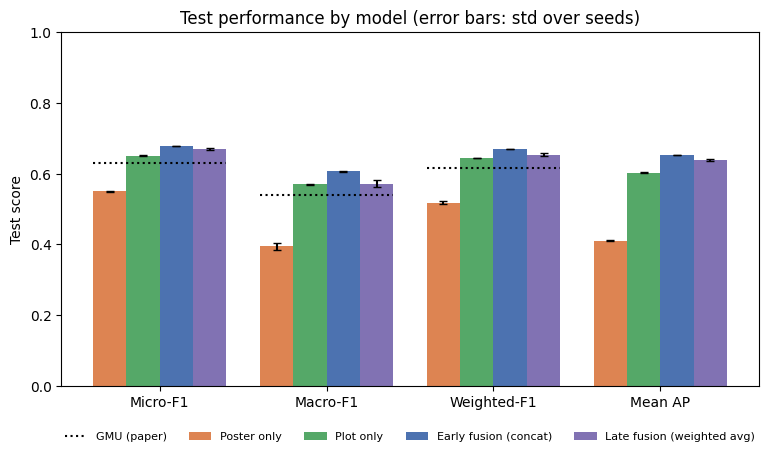

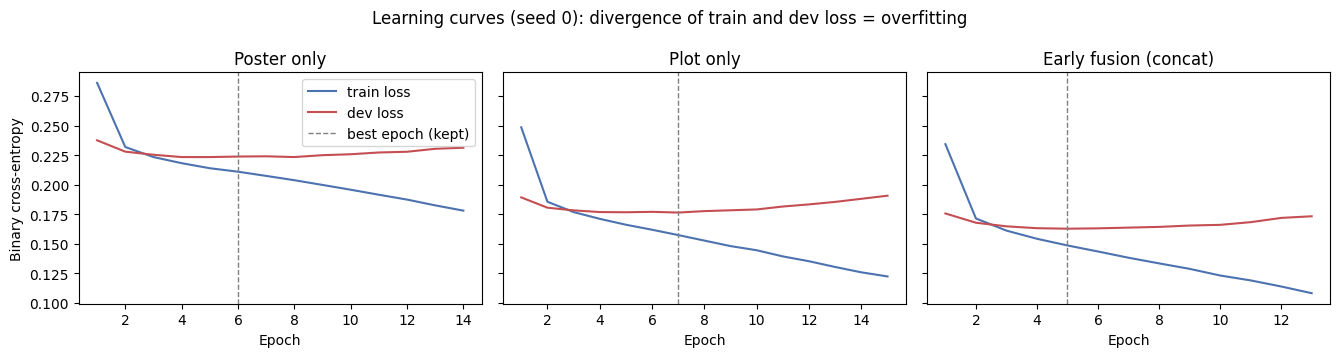

In [12]:
# Figure: headline metrics per model, with the GMU paper result as a dotted line
show = ['micro_f1', 'macro_f1', 'weighted_f1', 'mean_ap']
fig, ax = plt.subplots(figsize=(9, 4.6))
width = 0.8 / len(models)
for i, x in enumerate(models):
    ax.bar(np.arange(len(show)) + i * width, [agg.loc[x, (c, 'mean')] for c in show], width,
           yerr=[np.nan_to_num(agg.loc[x, (c, 'std')]) for c in show], capsize=3,
           label=MODEL_LABELS[x], color=COLORS[x])
gmu = PAPER_RESULTS['GMU (Arevalo et al., 2017)']
for j, c in enumerate(show):
    if c in gmu:
        ax.hlines(gmu[c], j - width / 2, j + width * (len(models) - 0.5), colors='black', linestyles=':',
                  label='GMU (paper)' if j == 0 else None)
ax.set_xticks(np.arange(len(show)) + width * (len(models) - 1) / 2)
ax.set_xticklabels(['Micro-F1', 'Macro-F1', 'Weighted-F1', 'Mean AP'])
ax.set_ylabel('Test score'); ax.set_ylim(0, 1)
ax.set_title('Test performance by model (error bars: std over seeds)')
ax.legend(ncol=5, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
save_fig(fig, 'model_comparison')

# Figure: learning curves (overfitting check)
curve_models = [x for x in ('image', 'text', 'early') if (HISTORY_DIR / f'{x}_seed0.json').exists()]
fig, axes = plt.subplots(1, len(curve_models), figsize=(4.5 * len(curve_models), 3.6), sharey=True, squeeze=False)
for ax, x in zip(axes[0], curve_models):
    h = json.loads((HISTORY_DIR / f'{x}_seed0.json').read_text())
    ax.plot(h['epoch'], h['train_loss'], label='train loss', color='#4C72B0')
    ax.plot(h['epoch'], h['dev_loss'], label='dev loss', color='#C44E52')
    ax.axvline(h['best_epoch'], ls='--', color='grey', lw=1, label='best epoch (kept)')
    ax.set_title(MODEL_LABELS[x]); ax.set_xlabel('Epoch')
axes[0][0].set_ylabel('Binary cross-entropy'); axes[0][0].legend()
fig.suptitle('Learning curves (seed 0): divergence of train and dev loss = overfitting')
fig.tight_layout()
save_fig(fig, 'learning_curves')

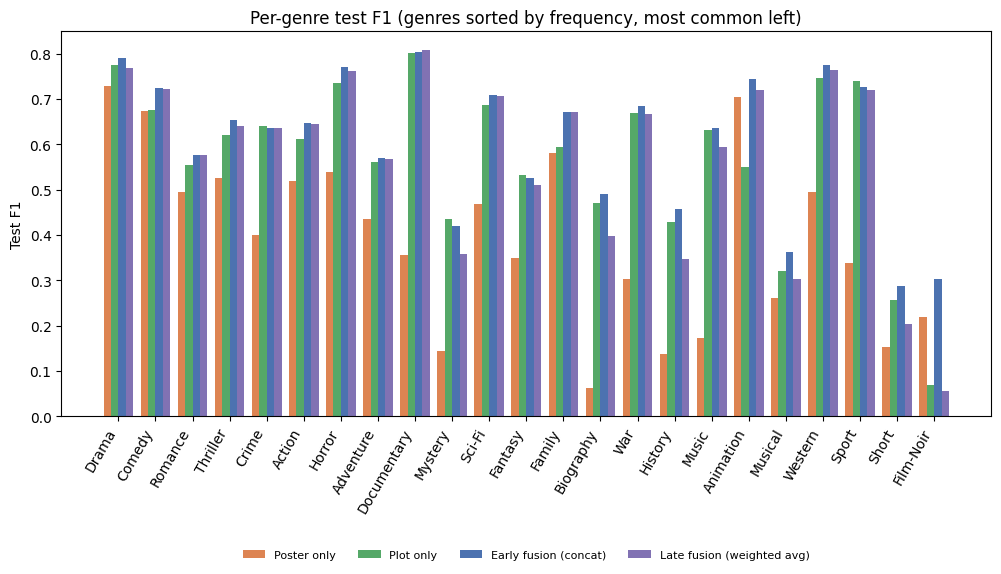

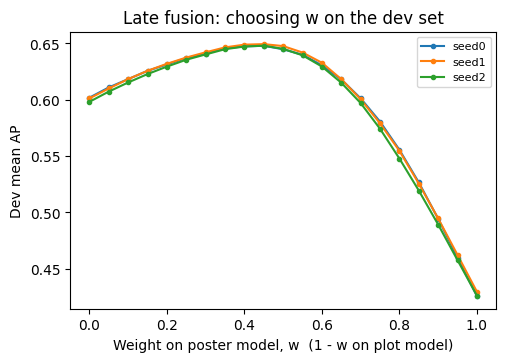

Early fusion (concat) beats the better single modality in 19 of 23 genres
Late fusion (weighted avg) beats the better single modality in 11 of 23 genres


,test support,Poster only,Plot only,Early fusion (concat),Late fusion (weighted avg)
Drama,4142,0.729,0.774,0.789,0.768
Comedy,2611,0.674,0.675,0.723,0.723
Romance,1590,0.495,0.554,0.576,0.576
Thriller,1567,0.526,0.620,0.655,0.640
Crime,1163,0.401,0.641,0.637,0.636
Action,1044,0.519,0.611,0.647,0.644
Horror,825,0.539,0.736,0.772,0.761
Adventure,821,0.436,0.561,0.569,0.568
Documentary,629,0.357,0.802,0.804,0.809
Mystery,617,0.145,0.436,0.421,0.358


In [13]:
# Per-genre F1: which genres each modality and fusion strategy is good at
pg = {MODEL_LABELS[x]: [np.mean([json.loads(f.read_text())[g]['f1'] for f in sorted(PER_GENRE_DIR.glob(f'{x}_seed*.json'))])
                        for g in GENRES] for x in models}
support = json.loads(sorted(PER_GENRE_DIR.glob('*.json'))[0].read_text())
pg_df = pd.DataFrame(pg, index=GENRES)
pg_df.insert(0, 'test support', [support[g]['support'] for g in GENRES])
pg_df = pg_df.sort_values('test support', ascending=False)
pg_df.round(3).to_csv(TABLES_DIR / 'per_genre_f1.csv', index_label='genre')

fig, ax = plt.subplots(figsize=(12, 5))
width = 0.8 / len(models)
for i, x in enumerate(models):
    ax.bar(np.arange(len(pg_df)) + i * width, pg_df[MODEL_LABELS[x]], width, label=MODEL_LABELS[x], color=COLORS[x])
ax.set_xticks(np.arange(len(pg_df)) + width * (len(models) - 1) / 2)
ax.set_xticklabels(pg_df.index, rotation=60, ha='right')
ax.set_ylabel('Test F1'); ax.set_title('Per-genre test F1 (genres sorted by frequency, most common left)')
ax.legend(ncol=len(models), fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.32), frameon=False)
save_fig(fig, 'per_genre_f1')

# Late fusion: dev mean AP as the poster weight w varies
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for f in sorted(HISTORY_DIR.glob('late_seed*.json')):
    h = json.loads(f.read_text())
    ax.plot(h['weights'], h['dev_map'], marker='o', ms=3, label=f.stem.replace('late_', ''))
ax.set_xlabel('Weight on poster model, w  (1 - w on plot model)'); ax.set_ylabel('Dev mean AP')
ax.set_title('Late fusion: choosing w on the dev set'); ax.legend(fontsize=8)
save_fig(fig, 'late_fusion_weight')

# Consistency: in how many genres does each fusion model beat the better single modality?
best_single = pg_df[[MODEL_LABELS['image'], MODEL_LABELS['text']]].max(axis=1)
for x in ('early', 'late'):
    print(f"{MODEL_LABELS[x]} beats the better single modality in "
          f"{int((pg_df[MODEL_LABELS[x]] > best_single).sum())} of {len(pg_df)} genres")
display(pg_df.round(3))

## References
- Arevalo, J., Solorio, T., Montes-y-Gómez, M. and González, F. A. (2017). Gated multimodal units for information fusion. ICLR Workshop. arXiv:1702.01992
- Radford, A. et al. (2021). Learning transferable visual models from natural language supervision. ICML. arXiv:2103.00020
- Reimers, N. and Gurevych, I. (2019). Sentence-BERT: sentence embeddings using Siamese BERT-networks. EMNLP. arXiv:1908.10084
- Song, K. et al. (2020). MPNet: masked and permuted pre-training for language understanding. NeurIPS. arXiv:2004.09297
- Loshchilov, I. and Hutter, F. (2019). Decoupled weight decay regularization. ICLR. arXiv:1711.05101
- Dataset: https://www.kaggle.com/datasets/johnarevalo/mmimdb